# Baseline walkthrough

This notebook only reads saved results, so it fits nothing and scores no test data.
To regenerate the results, run `make reproduce` from the repo root.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
m = json.loads((ROOT / "results/baseline/metrics.json").read_text())
k = json.loads((ROOT / "results/keep_duplicates/metrics.json").read_text())
print(f"N = {m['n']}, inputs = {m['n_inputs']}, dev = {m['n_dev']}, test = {m['n_test']} (not scored)")

N = 12205, inputs = 17, dev = 9764, test = 2441 (not scored)


## CV AUPRC

In [2]:
rows = [{"model": "Always no purchase", "C": None, "mean": m["floor"]["mean"],
         "SE": m["floor"]["se"], "fold SD": m["floor"]["sd"]}]
for name in ["with_pagevalues", "without_pagevalues"]:
    r = m[name]
    rows.append({"model": f"LR, {name}", "C": r["best_C"], "mean": r["mean"], "SE": r["se"], "fold SD": r["sd"]})
pd.DataFrame(rows).round(4)

,model,C,mean,SE,fold SD
0,Always no purchase,NaN,0.1563,0.0001,0.0002
1,"LR, with_pagevalues",0.0316,0.6484,0.0150,0.0334
2,"LR, without_pagevalues",0.1000,0.3312,0.0093,0.0208


## Tuning curve

Mean validation AUPRC at each `C`. The chosen `C` must not sit on the edge of the grid.

In [3]:
pd.read_csv(ROOT / "results/baseline/cv_curve.csv").round(4)

,C,with_pagevalues,without_pagevalues
0,0.0001,0.5402,0.2760
1,0.0003,0.5790,0.2845
2,0.0010,0.6175,0.3005
3,0.0032,0.6398,0.3162
4,0.0100,0.6481,0.3260
5,0.0316,0.6484,0.3299
6,0.1000,0.6461,0.3312
7,0.3162,0.6439,0.3308
8,1.0000,0.6422,0.3293
9,3.1623,0.6410,0.3276


## Is `PageValues` leaking the label?

These statistics fit leakage but do not prove it, so results are reported with and without it.

In [4]:
pd.Series(m["data_profile"]).round(3).to_frame("value")

,value
n_raw,12330.000
n_duplicates,125.000
duplicates_that_are_purchases,0.000
duplicates_that_are_bounces,125.000
dev_p_pagevalues_positive_given_purchase,0.803
dev_p_pagevalues_positive_given_no_purchase,0.116
dev_p_purchase_given_pagevalues_positive,0.562
dev_p_purchase_given_pagevalues_zero,0.040


## Pipeline check and duplicate sensitivity

In [5]:
c = m["shuffled_label_check"]
print(f"{c['n_shuffles']} label shuffles: {c['mean']:.3f} +/- {c['se']:.3f}; random scores: {c['chance_mean']:.3f}")
for name in ["with_pagevalues", "without_pagevalues"]:
    print(f"{name}: dropped {m[name]['mean']:.3f} +/- {m[name]['se']:.3f}; kept {k[name]['mean']:.3f} +/- {k[name]['se']:.3f}")

20 label shuffles: 0.159 +/- 0.001; random scores: 0.159
with_pagevalues: dropped 0.648 +/- 0.015; kept 0.644 +/- 0.013
without_pagevalues: dropped 0.331 +/- 0.009; kept 0.321 +/- 0.010


## Key figure

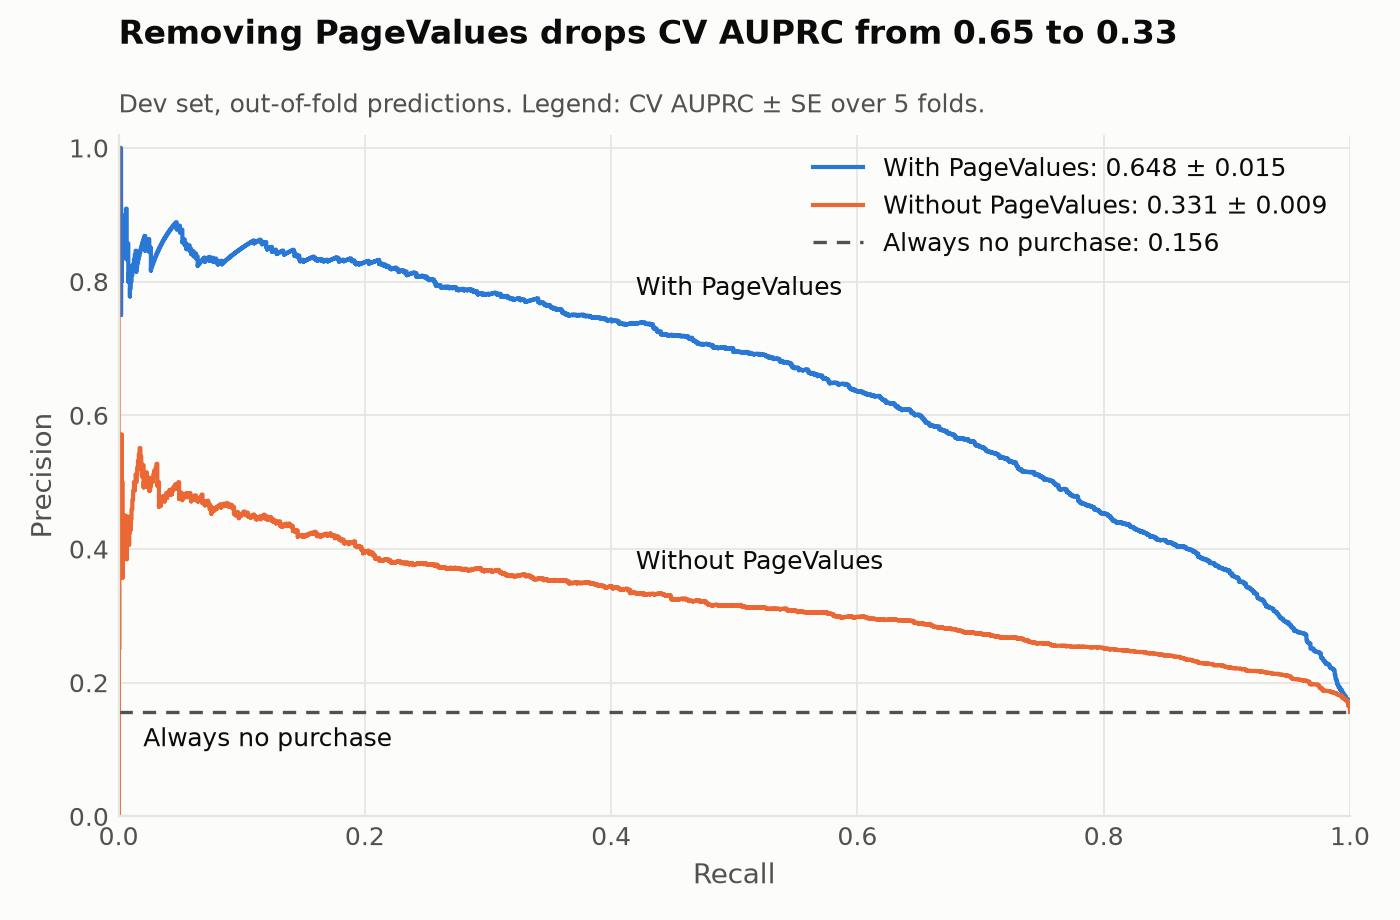

In [6]:
display(Image(filename=str(ROOT / "results/figures/baseline_pr_curve.png"), width=700))